# 05 — Sales Analysis

## Sales Order, Backlog & Inventory Analytics

### Objective

This notebook analyzes sales performance using the feature-engineered sales order and sales order item datasets.

The analysis focuses on:

- Overall sales performance
- Order volume and sales value
- Monthly, quarterly, and yearly sales trends
- Sales channel performance
- Customer segment performance
- Regional sales performance
- Product and category performance
- Order priority performance
- Average order value
- Discount analysis
- Profitability and margin performance
- Top-performing customers and products

Backlog, inventory, shipment, and supplier performance will be analyzed separately in their respective notebooks.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Pandas version     :", pd.__version__)
print("NumPy version      :", np.__version__)

print("\nSales Analysis environment initialized successfully.")

Pandas version     : 3.0.6
NumPy version      : 2.5.3

Sales Analysis environment initialized successfully.


## Step 2 — Define Feature-Engineered Data Path

Define the project directory and the location of the final feature-engineered datasets.

Sales Analysis will use the analysis-ready datasets produced by `04_Feature_Engineering.ipynb`.

In [2]:
# Define project paths

project_path = Path.cwd().parent

featured_data_path = (
    project_path / "data" / "featured"
)

print("Project Path       :", project_path)
print("Featured Data Path :", featured_data_path)

print(
    "\nFeatured Data Folder Exists :",
    featured_data_path.exists()
)

Project Path       : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics
Featured Data Path : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics\data\featured

Featured Data Folder Exists : True


## Step 3 — Load Sales Analysis Datasets

Load only the feature-engineered datasets required for Sales Analysis.

The datasets include:

- Sales Orders
- Sales Order Items
- Customers
- Products
- Warehouses

These tables provide the order, customer, product, geographic, and profitability information required for the sales analysis.

In [3]:
# Load datasets required for Sales Analysis

sales_orders = pd.read_csv(
    featured_data_path / "sales_orders_featured.csv",
    parse_dates=[
        "order_date",
        "requested_delivery_date"
    ]
)

sales_order_items = pd.read_csv(
    featured_data_path / "sales_order_items_featured.csv",
    parse_dates=["order_date"]
)

customers = pd.read_csv(
    featured_data_path / "customers_featured.csv",
    parse_dates=["customer_since"]
)

products = pd.read_csv(
    featured_data_path / "products_featured.csv"
)

warehouses = pd.read_csv(
    featured_data_path / "warehouses_featured.csv"
)


sales_datasets = {
    "Sales Orders": sales_orders,
    "Sales Order Items": sales_order_items,
    "Customers": customers,
    "Products": products,
    "Warehouses": warehouses
}


print("Sales Analysis datasets loaded successfully.\n")

for name, df in sales_datasets.items():
    print(
        f"{name:<20} "
        f"{df.shape[0]:>7,} rows × "
        f"{df.shape[1]:>2} columns"
    )

Sales Analysis datasets loaded successfully.

Sales Orders          25,000 rows × 26 columns
Sales Order Items     61,397 rows × 20 columns
Customers              2,500 rows ×  6 columns
Products                 500 rows × 10 columns
Warehouses                 6 rows ×  5 columns


## Step 4 — Overall Sales KPI Summary

Establish the core sales performance indicators for the complete analysis period.

The following KPIs are calculated:

- Total Orders
- Total Sales / Order Value
- Total Units Ordered
- Average Order Value (AOV)
- Average Units per Order
- Unique Customers

These KPIs provide the overall sales baseline before analyzing performance across time, channels, customers, regions, and products.

In [5]:
# Calculate overall sales KPIs

total_orders = sales_orders["order_id"].nunique()

total_sales = sales_orders["order_value"].sum()

total_units_ordered = sales_orders["ordered_qty"].sum()

average_order_value = (
    total_sales / total_orders
)

average_units_per_order = (
    total_units_ordered / total_orders
)

unique_customers = (
    sales_orders["customer_id"].nunique()
)


print("OVERALL SALES KPI SUMMARY\n")

print(
    f"Total Orders            : {total_orders:,}"
)

print(
    f"Total Sales Value       : {total_sales:,.2f}"
)

print(
    f"Total Units Ordered     : {total_units_ordered:,}"
)

print(
    f"Average Order Value     : {average_order_value:,.2f}"
)

print(
    f"Average Units per Order : {average_units_per_order:,.2f}"
)

print(
    f"Unique Customers        : {unique_customers:,}"
)

OVERALL SALES KPI SUMMARY

Total Orders            : 25,000
Total Sales Value       : 2,068,495,699.27
Total Units Ordered     : 501,755
Average Order Value     : 82,739.83
Average Units per Order : 20.07
Unique Customers        : 2,500


## Step 5 — Yearly Sales Performance

Analyze sales performance by year to understand how order volume, units ordered, sales value, and average order value change over time.

The analysis includes:

- Total Orders
- Total Units Ordered
- Total Sales Value
- Average Order Value

In [6]:
# Calculate yearly sales performance

yearly_sales = (
    sales_orders
    .groupby("order_year")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

yearly_sales["average_order_value"] = (
    yearly_sales["total_sales"]
    / yearly_sales["total_orders"]
)

yearly_sales = yearly_sales.sort_values(
    "order_year"
).reset_index(drop=True)


print("YEARLY SALES PERFORMANCE\n")

print(
    yearly_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

YEARLY SALES PERFORMANCE

 order_year total_orders total_units    total_sales average_order_value
       2024        9,273     184,630 758,432,217.52           81,789.30
       2025        9,356     189,406 781,527,209.58           83,532.19
       2026        6,371     127,719 528,536,272.17           82,959.70


## Step 6 — Monthly Sales Trend

Analyze sales performance at the Year-Month level to identify changes in sales activity over time.

The monthly analysis includes:

- Total Orders
- Total Units Ordered
- Total Sales Value
- Average Order Value

Year-Month is used instead of month name alone to preserve chronological order across multiple years.

In [7]:
# Calculate monthly sales performance

monthly_sales = (
    sales_orders
    .groupby("order_year_month")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

monthly_sales["average_order_value"] = (
    monthly_sales["total_sales"]
    / monthly_sales["total_orders"]
)

monthly_sales = monthly_sales.sort_values(
    "order_year_month"
).reset_index(drop=True)


print("MONTHLY SALES PERFORMANCE\n")

print(
    monthly_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

print(
    "\nNumber of Months :",
    len(monthly_sales)
)

MONTHLY SALES PERFORMANCE

order_year_month total_orders total_units   total_sales average_order_value
         2024-01          673      13,192 52,135,308.86           77,467.03
         2024-02          601      12,221 48,269,011.44           80,314.49
         2024-03          678      13,253 54,981,584.88           81,093.78
         2024-04          676      13,645 57,131,162.04           84,513.55
         2024-05          748      14,727 61,435,434.71           82,132.93
         2024-06          697      13,552 57,582,844.32           82,615.27
         2024-07          640      12,813 52,964,382.54           82,756.85
         2024-08          786      15,375 63,522,442.49           80,817.36
         2024-09          815      17,126 68,724,015.91           84,323.95
         2024-10          914      17,935 74,320,450.14           81,313.40
         2024-11          985      19,216 77,205,458.07           78,381.18
         2024-12        1,060      21,575 90,160,122.12      

## Step 7 — Monthly Sales Trend Visualization

Visualize monthly sales value across the analysis period to identify:

- Overall sales movement
- Growth or decline patterns
- Peak sales periods
- Potential seasonality

The Year-Month field is used to maintain chronological order.

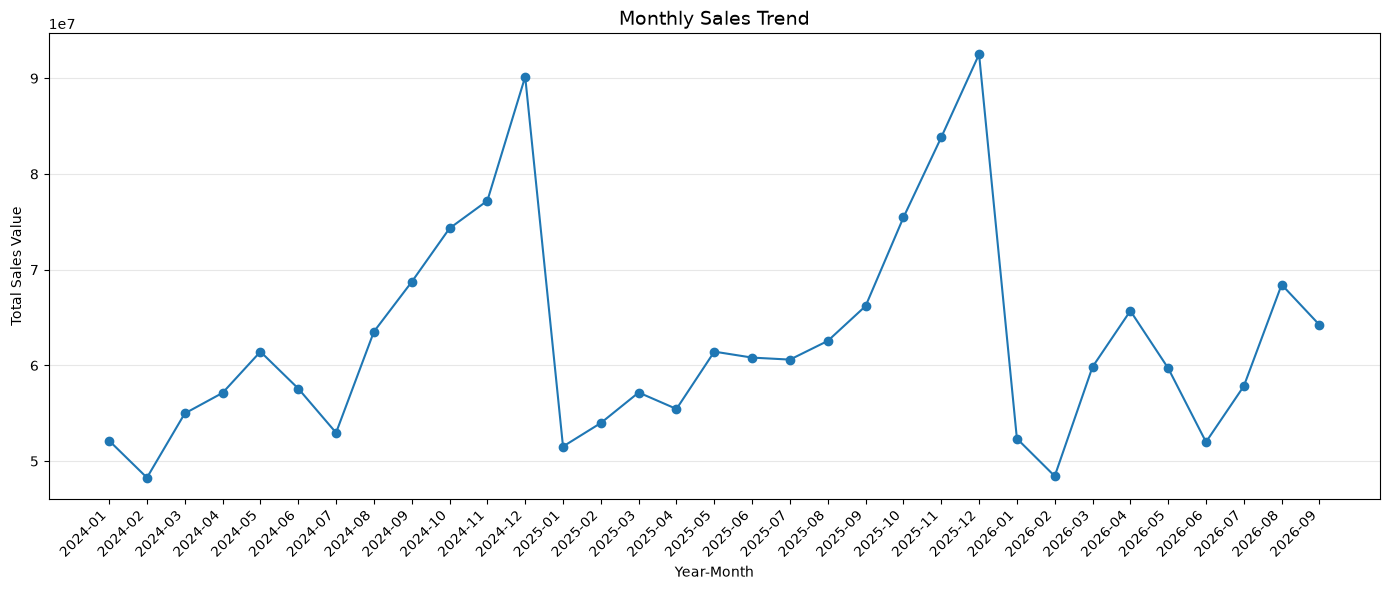

In [8]:
# Visualize monthly sales trend

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["order_year_month"],
    monthly_sales["total_sales"],
    marker="o"
)

plt.title(
    "Monthly Sales Trend",
    fontsize=14
)

plt.xlabel("Year-Month")
plt.ylabel("Total Sales Value")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()

## Step 8 — Month-of-Year Sales Performance

Analyze sales by calendar month across the available years to identify recurring seasonal patterns.

The analysis compares:

- Total Orders
- Total Units Ordered
- Total Sales Value
- Average Order Value

Calendar months are sorted using `order_month_no` rather than alphabetically.

In [9]:
# Calculate month-of-year sales performance

month_sales = (
    sales_orders
    .groupby(
        ["order_month_no", "order_month"]
    )
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

month_sales["average_order_value"] = (
    month_sales["total_sales"]
    / month_sales["total_orders"]
)

month_sales = (
    month_sales
    .sort_values("order_month_no")
    .reset_index(drop=True)
)


print("MONTH-OF-YEAR SALES PERFORMANCE\n")

print(
    month_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

MONTH-OF-YEAR SALES PERFORMANCE

 order_month_no order_month total_orders total_units    total_sales average_order_value
              1     January        1,937      38,414 156,013,427.13           80,543.84
              2    February        1,854      36,977 150,682,564.51           81,274.31
              3       March        2,041      41,185 171,994,381.97           84,269.66
              4       April        2,088      42,882 178,280,480.65           85,383.37
              5         May        2,242      44,513 182,578,027.30           81,435.34
              6        June        2,059      40,813 170,395,708.40           82,756.54
              7        July        2,074      41,340 171,404,529.44           82,644.42
              8      August        2,290      46,590 194,518,295.91           84,942.49
              9   September        2,386      48,993 199,154,082.63           83,467.76
             10     October        1,830      36,612 149,775,013.08           81,844.27

## Step 9 — Sales Channel Performance

Analyze sales performance across sales channels to understand how each channel contributes to overall revenue and order activity.

The analysis includes:

- Total Orders
- Total Units Ordered
- Total Sales Value
- Sales Contribution %
- Average Order Value

In [10]:
# Calculate sales channel performance

channel_sales = (
    sales_orders
    .groupby("sales_channel")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

channel_sales["sales_contribution_pct"] = (
    channel_sales["total_sales"]
    / channel_sales["total_sales"].sum()
) * 100

channel_sales["average_order_value"] = (
    channel_sales["total_sales"]
    / channel_sales["total_orders"]
)

channel_sales = (
    channel_sales
    .sort_values(
        "total_sales",
        ascending=False
    )
    .reset_index(drop=True)
)


print("SALES CHANNEL PERFORMANCE\n")

print(
    channel_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "sales_contribution_pct": "{:,.2f}%".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

SALES CHANNEL PERFORMANCE

sales_channel total_orders total_units    total_sales sales_contribution_pct average_order_value
       Online        7,851     157,738 645,216,635.68                 31.19%           82,182.73
       Direct        7,195     146,393 610,985,120.25                 29.54%           84,918.02
  Distributor        5,469     109,514 452,511,367.51                 21.88%           82,741.15
  Marketplace        4,485      88,110 359,782,575.83                 17.39%           80,219.08


## Step 10 — Customer Segment Sales Performance

Analyze sales performance across customer segments to understand which types of customers contribute most to revenue and order activity.

The analysis includes:

- Total Orders
- Unique Customers
- Total Units Ordered
- Total Sales Value
- Sales Contribution %
- Average Order Value

In [11]:
# Add customer segment to sales orders

sales_customer = sales_orders.merge(
    customers[
        [
            "customer_id",
            "customer_segment"
        ]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)


# Calculate customer segment performance

segment_sales = (
    sales_customer
    .groupby("customer_segment")
    .agg(
        total_orders=("order_id", "nunique"),
        unique_customers=("customer_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

segment_sales["sales_contribution_pct"] = (
    segment_sales["total_sales"]
    / segment_sales["total_sales"].sum()
) * 100

segment_sales["average_order_value"] = (
    segment_sales["total_sales"]
    / segment_sales["total_orders"]
)

segment_sales = (
    segment_sales
    .sort_values(
        "total_sales",
        ascending=False
    )
    .reset_index(drop=True)
)


print("CUSTOMER SEGMENT SALES PERFORMANCE\n")

print(
    segment_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "unique_customers": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "sales_contribution_pct": "{:,.2f}%".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

print(
    "\nMissing Customer Segment After Merge :",
    sales_customer["customer_segment"].isna().sum()
)

CUSTOMER SEGMENT SALES PERFORMANCE

customer_segment total_orders unique_customers total_units    total_sales sales_contribution_pct average_order_value
          Retail        9,269              931     186,425 769,761,383.63                 37.21%           83,046.86
             SMB        7,856              786     157,154 648,860,245.76                 31.37%           82,594.23
      Enterprise        4,298              420      86,304 351,773,516.38                 17.01%           81,845.86
     Distributor        3,577              363      71,872 298,100,553.50                 14.41%           83,338.15

Missing Customer Segment After Merge : 0


## Step 11 — Regional Sales Performance

Analyze sales performance by customer region to understand the geographic distribution of customer demand.

The analysis includes:

- Total Orders
- Unique Customers
- Total Units Ordered
- Total Sales Value
- Sales Contribution %
- Average Order Value

Customer region is used to represent the geographic source of sales demand.

In [12]:
# Add customer region to sales orders

sales_region = sales_orders.merge(
    customers[
        [
            "customer_id",
            "region"
        ]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)


# Calculate regional sales performance

regional_sales = (
    sales_region
    .groupby("region")
    .agg(
        total_orders=("order_id", "nunique"),
        unique_customers=("customer_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

regional_sales["sales_contribution_pct"] = (
    regional_sales["total_sales"]
    / regional_sales["total_sales"].sum()
) * 100

regional_sales["average_order_value"] = (
    regional_sales["total_sales"]
    / regional_sales["total_orders"]
)

regional_sales = (
    regional_sales
    .sort_values(
        "total_sales",
        ascending=False
    )
    .reset_index(drop=True)
)


print("REGIONAL SALES PERFORMANCE\n")

print(
    regional_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "unique_customers": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "sales_contribution_pct": "{:,.2f}%".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

print(
    "\nMissing Customer Region After Merge :",
    sales_region["region"].isna().sum()
)

REGIONAL SALES PERFORMANCE

 region total_orders unique_customers total_units    total_sales sales_contribution_pct average_order_value
  South        6,995              707     140,654 582,177,703.91                 28.14%           83,227.69
   West        6,198              621     123,862 513,947,666.56                 24.85%           82,921.53
  North        4,741              470      96,713 394,825,307.79                 19.09%           83,278.91
   East        3,906              386      78,534 323,117,163.24                 15.62%           82,723.29
Central        3,160              316      61,992 254,427,857.77                 12.30%           80,515.14

Missing Customer Region After Merge : 0


## Step 12 — Product Category Sales Performance

Analyze sales performance across product categories using sales order line-item data.

The analysis includes:

- Total Order Lines
- Total Units Ordered
- Net Sales Value
- Sales Contribution %
- Average Sales Value per Order Line

Net order value is used because it reflects the line value after discounts.

In [13]:
# Add product category to sales order items

sales_product = sales_order_items.merge(
    products[
        [
            "product_id",
            "category"
        ]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)


# Calculate product category sales performance

category_sales = (
    sales_product
    .groupby("category")
    .agg(
        total_order_lines=("order_item_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        net_sales=("net_order_value", "sum")
    )
    .reset_index()
)

category_sales["sales_contribution_pct"] = (
    category_sales["net_sales"]
    / category_sales["net_sales"].sum()
) * 100

category_sales["avg_sales_per_line"] = (
    category_sales["net_sales"]
    / category_sales["total_order_lines"]
)

category_sales = (
    category_sales
    .sort_values(
        "net_sales",
        ascending=False
    )
    .reset_index(drop=True)
)


print("PRODUCT CATEGORY SALES PERFORMANCE\n")

print(
    category_sales.to_string(
        index=False,
        formatters={
            "total_order_lines": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "net_sales": "{:,.2f}".format,
            "sales_contribution_pct": "{:,.2f}%".format,
            "avg_sales_per_line": "{:,.2f}".format
        }
    )
)

print(
    "\nMissing Product Category After Merge :",
    sales_product["category"].isna().sum()
)

PRODUCT CATEGORY SALES PERFORMANCE

              category total_order_lines total_units      net_sales sales_contribution_pct avg_sales_per_line
           Electronics            16,347     134,143 594,394,618.00                 28.74%          36,361.08
       Office Supplies            11,401      92,730 392,745,467.90                 18.99%          34,448.34
        Home & Kitchen            11,584      95,924 379,346,698.56                 18.34%          32,747.47
Health & Personal Care            11,161      90,438 367,898,426.65                 17.79%          32,962.86
            Automotive            10,904      88,520 334,110,488.16                 16.15%          30,641.09

Missing Product Category After Merge : 0


## Step 13 — Top 10 Products by Net Sales

Identify the highest-performing individual products based on net sales value.

The analysis includes:

- Total Order Lines
- Total Units Sold
- Net Sales Value
- Gross Profit
- Average Profit Margin %

This helps identify products that contribute most strongly to sales and profitability.

In [14]:
# Add product name to sales product dataset

sales_product = sales_product.merge(
    products[
        [
            "product_id",
            "product_name"
        ]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)


# Calculate product-level performance

product_sales = (
    sales_product
    .groupby(
        ["product_id", "product_name"]
    )
    .agg(
        total_order_lines=("order_item_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        net_sales=("net_order_value", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

product_sales["profit_margin_pct"] = (
    product_sales["gross_profit"]
    / product_sales["net_sales"]
) * 100


top_10_products = (
    product_sales
    .sort_values(
        "net_sales",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)


print("TOP 10 PRODUCTS BY NET SALES\n")

print(
    top_10_products.to_string(
        index=False,
        formatters={
            "total_order_lines": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "net_sales": "{:,.2f}".format,
            "gross_profit": "{:,.2f}".format,
            "profit_margin_pct": "{:,.2f}%".format
        }
    )
)

print(
    "\nMissing Product Name After Merge :",
    sales_product["product_name"].isna().sum()
)

TOP 10 PRODUCTS BY NET SALES

product_id               product_name total_order_lines total_units     net_sales  gross_profit profit_margin_pct
   SKU0228 Smart Devices Product 0228               635       4,980 44,867,981.77 12,663,765.97            28.22%
   SKU0157      Grooming Product 0157               575       4,590 35,066,275.52  6,281,100.32            17.91%
   SKU0029   Maintenance Product 0029               582       4,387 29,447,744.44  4,702,212.89            15.97%
   SKU0006   Accessories Product 0006               370       3,412 23,994,519.01  5,050,105.53            21.05%
   SKU0327     Furniture Product 0327               356       2,879 20,727,267.24  5,839,699.13            28.17%
   SKU0201      Cookware Product 0201               281       2,385 17,305,493.36  4,856,389.61            28.06%
   SKU0113 Personal Care Product 0113               400       2,954 16,873,854.90  4,903,803.80            29.06%
   SKU0074   Maintenance Product 0074               320   

## Step 14 — Top 10 Customers by Sales

Identify the highest-value customers based on total sales generated.

The analysis includes:

- Total Orders
- Total Units Ordered
- Total Sales Value
- Average Order Value

This helps identify customers with the greatest contribution to overall sales.

In [15]:
# Add customer name to sales orders

customer_sales_data = sales_orders.merge(
    customers[
        [
            "customer_id",
            "customer_name"
        ]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)


# Calculate customer-level sales performance

customer_sales = (
    customer_sales_data
    .groupby(
        ["customer_id", "customer_name"]
    )
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

customer_sales["average_order_value"] = (
    customer_sales["total_sales"]
    / customer_sales["total_orders"]
)


top_10_customers = (
    customer_sales
    .sort_values(
        "total_sales",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)


print("TOP 10 CUSTOMERS BY SALES\n")

print(
    top_10_customers.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

print(
    "\nMissing Customer Name After Merge :",
    customer_sales_data["customer_name"].isna().sum()
)

TOP 10 CUSTOMERS BY SALES

customer_id  customer_name total_orders total_units  total_sales average_order_value
  CUST00868 Customer 00868           12         462 2,318,306.15          193,192.18
  CUST00994 Customer 00994           15         439 2,227,477.46          148,498.50
  CUST01764 Customer 01764           19         535 2,213,333.33          116,491.23
  CUST01388 Customer 01388           14         401 2,200,107.81          157,150.56
  CUST02281 Customer 02281           14         372 2,086,680.62          149,048.62
  CUST00798 Customer 00798           19         422 2,070,509.96          108,974.21
  CUST01496 Customer 01496           15         421 2,056,915.43          137,127.70
  CUST00682 Customer 00682           17         446 2,053,921.79          120,818.93
  CUST01832 Customer 01832           20         477 2,035,854.13          101,792.71
  CUST00872 Customer 00872           15         407 2,006,914.66          133,794.31

Missing Customer Name After Merge : 0

## Step 15 — Sales Performance by Order Priority

Analyze sales performance across order priority levels.

The analysis includes:

- Total Orders
- Total Units Ordered
- Total Sales Value
- Sales Contribution %
- Average Order Value

This provides visibility into the commercial value associated with different order-priority groups.

In [16]:
# Calculate sales performance by order priority

priority_sales = (
    sales_orders
    .groupby("priority")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

priority_sales["sales_contribution_pct"] = (
    priority_sales["total_sales"]
    / priority_sales["total_sales"].sum()
) * 100

priority_sales["average_order_value"] = (
    priority_sales["total_sales"]
    / priority_sales["total_orders"]
)

priority_sales = (
    priority_sales
    .sort_values(
        "total_sales",
        ascending=False
    )
    .reset_index(drop=True)
)


print("SALES PERFORMANCE BY ORDER PRIORITY\n")

print(
    priority_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "sales_contribution_pct": "{:,.2f}%".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

SALES PERFORMANCE BY ORDER PRIORITY

priority total_orders total_units      total_sales sales_contribution_pct average_order_value
  Normal       14,557     292,757 1,211,743,876.22                 58.58%           83,241.32
    High        6,359     129,220   530,722,450.84                 25.66%           83,460.05
  Urgent        2,049      40,090   163,578,344.67                  7.91%           79,833.26
     Low        2,035      39,688   162,451,027.54                  7.85%           79,828.51


## Step 16 — Discount Performance Analysis

Analyze sales and profitability across discount levels.

The analysis includes:

- Total Order Lines
- Total Units Ordered
- Net Sales Value
- Gross Profit
- Profit Margin %

This helps evaluate how discounting relates to revenue and profitability.

In [17]:
# Calculate performance by discount level

discount_sales = (
    sales_order_items
    .groupby("discount_pct")
    .agg(
        total_order_lines=("order_item_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        net_sales=("net_order_value", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

discount_sales["profit_margin_pct"] = (
    discount_sales["gross_profit"]
    / discount_sales["net_sales"]
) * 100

discount_sales = (
    discount_sales
    .sort_values("discount_pct")
    .reset_index(drop=True)
)

# Display discount as percentage
discount_sales["discount_level"] = (
    discount_sales["discount_pct"] * 100
)


print("DISCOUNT PERFORMANCE ANALYSIS\n")

print(
    discount_sales[
        [
            "discount_level",
            "total_order_lines",
            "total_units",
            "net_sales",
            "gross_profit",
            "profit_margin_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "discount_level": "{:.0f}%".format,
            "total_order_lines": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "net_sales": "{:,.2f}".format,
            "gross_profit": "{:,.2f}".format,
            "profit_margin_pct": "{:,.2f}%".format
        }
    )
)

DISCOUNT PERFORMANCE ANALYSIS

discount_level total_order_lines total_units      net_sales   gross_profit profit_margin_pct
            0%            21,405     174,749 758,201,743.45 174,779,138.70            23.05%
            2%             6,083      50,122 210,621,454.59  45,657,668.80            21.68%
            5%            13,566     111,254 456,958,996.56  86,974,420.44            19.03%
            8%             7,377      60,523 238,809,283.09  39,787,706.91            16.66%
           10%             9,857      80,054 312,472,567.14  44,994,427.93            14.40%
           15%             3,109      25,053  91,431,654.44   8,665,878.14             9.48%


## Step 17 — Overall Profitability KPIs

Evaluate the overall profitability of sales using line-item financial data.

The analysis includes:

- Total Net Sales
- Total Cost
- Total Gross Profit
- Overall Gross Profit Margin %
- Profitable Order Lines
- Loss-Making Order Lines

These KPIs establish the overall profitability baseline for the sales portfolio.

In [18]:
# Calculate overall profitability KPIs

total_net_sales = (
    sales_order_items["net_order_value"].sum()
)

total_cost = (
    sales_order_items["line_cost"].sum()
)

total_gross_profit = (
    sales_order_items["gross_profit"].sum()
)

overall_profit_margin = (
    total_gross_profit
    / total_net_sales
) * 100

profitable_lines = (
    sales_order_items["gross_profit"] > 0
).sum()

loss_making_lines = (
    sales_order_items["gross_profit"] < 0
).sum()

break_even_lines = (
    sales_order_items["gross_profit"] == 0
).sum()


print("OVERALL PROFITABILITY KPI SUMMARY\n")

print(
    f"Total Net Sales          : {total_net_sales:,.2f}"
)

print(
    f"Total Cost               : {total_cost:,.2f}"
)

print(
    f"Total Gross Profit       : {total_gross_profit:,.2f}"
)

print(
    f"Overall Profit Margin    : {overall_profit_margin:,.2f}%"
)

print(
    f"Profitable Order Lines   : {profitable_lines:,}"
)

print(
    f"Loss-Making Order Lines  : {loss_making_lines:,}"
)

print(
    f"Break-Even Order Lines   : {break_even_lines:,}"
)

OVERALL PROFITABILITY KPI SUMMARY

Total Net Sales          : 2,068,495,699.27
Total Cost               : 1,667,636,458.35
Total Gross Profit       : 400,859,240.92
Overall Profit Margin    : 19.38%
Profitable Order Lines   : 60,897
Loss-Making Order Lines  : 500
Break-Even Order Lines   : 0


## Step 18 — Category Profitability Analysis

Analyze profitability across product categories to determine which categories generate the greatest profit and which achieve the strongest margins.

The analysis includes:

- Net Sales
- Total Cost
- Gross Profit
- Profit Margin %
- Profit Contribution %

This provides a profitability perspective in addition to the sales-volume analysis performed earlier.

In [19]:
# Calculate category profitability

category_profit = (
    sales_product
    .groupby("category")
    .agg(
        net_sales=("net_order_value", "sum"),
        total_cost=("line_cost", "sum"),
        gross_profit=("gross_profit", "sum")
    )
    .reset_index()
)

category_profit["profit_margin_pct"] = (
    category_profit["gross_profit"]
    / category_profit["net_sales"]
) * 100

category_profit["profit_contribution_pct"] = (
    category_profit["gross_profit"]
    / category_profit["gross_profit"].sum()
) * 100

category_profit = (
    category_profit
    .sort_values(
        "gross_profit",
        ascending=False
    )
    .reset_index(drop=True)
)


print("CATEGORY PROFITABILITY ANALYSIS\n")

print(
    category_profit.to_string(
        index=False,
        formatters={
            "net_sales": "{:,.2f}".format,
            "total_cost": "{:,.2f}".format,
            "gross_profit": "{:,.2f}".format,
            "profit_margin_pct": "{:,.2f}%".format,
            "profit_contribution_pct": "{:,.2f}%".format
        }
    )
)

CATEGORY PROFITABILITY ANALYSIS

              category      net_sales     total_cost   gross_profit profit_margin_pct profit_contribution_pct
           Electronics 594,394,618.00 475,774,210.01 118,620,407.99            19.96%                  29.59%
       Office Supplies 392,745,467.90 315,593,564.54  77,151,903.36            19.64%                  19.25%
Health & Personal Care 367,898,426.65 294,910,149.19  72,988,277.46            19.84%                  18.21%
        Home & Kitchen 379,346,698.56 309,356,509.85  69,990,188.71            18.45%                  17.46%
            Automotive 334,110,488.16 272,002,024.76  62,108,463.40            18.59%                  15.49%


## Step 19 — Comparable Year-over-Year Sales Growth

Calculate year-over-year sales growth using a comparable January–September period for each year.

Since the dataset ends in September 2026, comparing full-year 2024 or 2025 directly with 2026 would produce a misleading result.

Therefore, this analysis compares the same nine-month period across all available years.

The analysis includes:

- January–September Sales
- January–September Orders
- Year-over-Year Sales Growth %

In [20]:
# Filter comparable January-September period

comparable_sales = sales_orders[
    sales_orders["order_month_no"] <= 9
].copy()


# Calculate comparable yearly performance

yoy_sales = (
    comparable_sales
    .groupby("order_year")
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
    .sort_values("order_year")
)

yoy_sales["yoy_sales_growth_pct"] = (
    yoy_sales["total_sales"]
    .pct_change() * 100
)


print("COMPARABLE JAN-SEP YEAR-OVER-YEAR SALES\n")

print(
    yoy_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "yoy_sales_growth_pct":
                lambda x: ""
                if pd.isna(x)
                else f"{x:,.2f}%"
        }
    )
)

COMPARABLE JAN-SEP YEAR-OVER-YEAR SALES

 order_year total_orders    total_sales yoy_sales_growth_pct
       2024        6,314 516,746,187.19                  NaN
       2025        6,286 529,739,038.58                2.51%
       2026        6,371 528,536,272.17               -0.23%


## Step 20 — Quarterly Sales Performance

Analyze sales performance by year and quarter to identify shorter-term changes in commercial performance.

The analysis includes:

- Total Orders
- Total Units Ordered
- Total Sales Value
- Average Order Value

Quarterly analysis provides more detail than annual totals while remaining less volatile than monthly performance.

In [21]:
# Calculate quarterly sales performance

quarterly_sales = (
    sales_orders
    .groupby(
        ["order_year", "order_quarter"]
    )
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

quarterly_sales["average_order_value"] = (
    quarterly_sales["total_sales"]
    / quarterly_sales["total_orders"]
)

quarterly_sales["quarter_no"] = (
    quarterly_sales["order_quarter"]
    .str.replace("Q", "", regex=False)
    .astype(int)
)

quarterly_sales = (
    quarterly_sales
    .sort_values(
        ["order_year", "quarter_no"]
    )
    .drop(columns="quarter_no")
    .reset_index(drop=True)
)


print("QUARTERLY SALES PERFORMANCE\n")

print(
    quarterly_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

QUARTERLY SALES PERFORMANCE

 order_year order_quarter total_orders total_units    total_sales average_order_value
       2024            Q1        1,952      38,666 155,385,905.18           79,603.44
       2024            Q2        2,121      41,924 176,149,441.07           83,050.18
       2024            Q3        2,241      45,314 185,210,840.94           82,646.52
       2024            Q4        2,959      58,726 241,686,030.33           81,678.28
       2025            Q1        1,915      39,129 162,673,333.71           84,946.91
       2025            Q2        2,128      43,132 177,701,748.68           83,506.46
       2025            Q3        2,243      45,823 189,363,956.19           84,424.41
       2025            Q4        3,070      61,322 251,788,171.00           82,015.69
       2026            Q1        1,965      38,781 160,631,134.72           81,746.12
       2026            Q2        2,140      43,152 177,403,026.60           82,898.61
       2026            Q3

## Step 21 — Top 10 Products by Gross Profit

Identify the products generating the highest total gross profit.

This analysis complements the Top Products by Net Sales analysis by showing whether the highest-revenue products are also the strongest profit contributors.

The analysis includes:

- Net Sales
- Gross Profit
- Profit Margin %
- Total Units Sold

In [22]:
# Identify top 10 products by gross profit

top_10_profit_products = (
    product_sales
    .sort_values(
        "gross_profit",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)


print("TOP 10 PRODUCTS BY GROSS PROFIT\n")

print(
    top_10_profit_products[
        [
            "product_id",
            "product_name",
            "total_units",
            "net_sales",
            "gross_profit",
            "profit_margin_pct"
        ]
    ].to_string(
        index=False,
        formatters={
            "total_units": "{:,.0f}".format,
            "net_sales": "{:,.2f}".format,
            "gross_profit": "{:,.2f}".format,
            "profit_margin_pct": "{:,.2f}%".format
        }
    )
)

TOP 10 PRODUCTS BY GROSS PROFIT

product_id               product_name total_units     net_sales  gross_profit profit_margin_pct
   SKU0228 Smart Devices Product 0228       4,980 44,867,981.77 12,663,765.97            28.22%
   SKU0157      Grooming Product 0157       4,590 35,066,275.52  6,281,100.32            17.91%
   SKU0327     Furniture Product 0327       2,879 20,727,267.24  5,839,699.13            28.17%
   SKU0006   Accessories Product 0006       3,412 23,994,519.01  5,050,105.53            21.05%
   SKU0113 Personal Care Product 0113       2,954 16,873,854.90  4,903,803.80            29.06%
   SKU0201      Cookware Product 0201       2,385 17,305,493.36  4,856,389.61            28.06%
   SKU0029   Maintenance Product 0029       4,387 29,447,744.44  4,702,212.89            15.97%
   SKU0217     Furniture Product 0217       4,047 15,402,725.90  3,783,141.38            24.56%
   SKU0399         Audio Product 0399       1,919 15,092,461.79  3,757,274.21            24.90%
   SKU0

## Step 22 — Loss-Making Product Analysis

Analyze products associated with loss-making sales lines.

This analysis identifies:

- Number of loss-making order lines
- Units sold at a loss
- Net sales generated from loss-making lines
- Total gross loss
- Average profit margin on loss-making lines

This helps identify products where discounting and product cost create profitability risk.

In [23]:
# Filter loss-making sales lines

loss_lines = sales_product[
    sales_product["gross_profit"] < 0
].copy()


# Calculate loss-making product performance

loss_product_analysis = (
    loss_lines
    .groupby(
        ["product_id", "product_name"]
    )
    .agg(
        loss_making_lines=("order_item_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        net_sales=("net_order_value", "sum"),
        gross_loss=("gross_profit", "sum")
    )
    .reset_index()
)

loss_product_analysis["avg_profit_margin_pct"] = (
    loss_product_analysis["gross_loss"]
    / loss_product_analysis["net_sales"]
) * 100


# Rank products by greatest absolute loss

loss_product_analysis = (
    loss_product_analysis
    .sort_values("gross_loss")
    .reset_index(drop=True)
)


print("TOP 10 PRODUCTS BY GROSS LOSS\n")

print(
    loss_product_analysis
    .head(10)
    .to_string(
        index=False,
        formatters={
            "loss_making_lines": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "net_sales": "{:,.2f}".format,
            "gross_loss": "{:,.2f}".format,
            "avg_profit_margin_pct": "{:,.2f}%".format
        }
    )
)

print(
    "\nTotal Loss-Making Lines :",
    len(loss_lines)
)

print(
    "Products With Loss-Making Lines :",
    loss_product_analysis["product_id"].nunique()
)

print(
    "Total Gross Loss :",
    f"{loss_lines['gross_profit'].sum():,.2f}"
)

TOP 10 PRODUCTS BY GROSS LOSS

product_id               product_name loss_making_lines total_units  net_sales gross_loss avg_profit_margin_pct
   SKU0161       Storage Product 0161                10         136 702,757.83 -32,828.09                -4.67%
   SKU0016         Audio Product 0016                 9         160 818,903.60 -22,016.40                -2.69%
   SKU0314    Stationery Product 0314                 6         117 677,844.23 -14,007.19                -2.07%
   SKU0076     Furniture Product 0076                 4          84 468,116.97 -12,502.47                -2.67%
   SKU0268 Smart Devices Product 0268                 7          49 293,036.51 -11,636.67                -3.97%
   SKU0150 Smart Devices Product 0150                 8         122 310,881.20 -10,008.08                -3.22%
   SKU0060     Furniture Product 0060                 7          75 451,366.58  -9,901.42                -2.19%
   SKU0444    Appliances Product 0444                10          68 317,1

## Step 23 — Sales Concentration Analysis

Measure how concentrated overall sales are among the highest-value customers and products.

The analysis evaluates:

- Top 10 Customer Sales Contribution %
- Top 10 Product Sales Contribution %

This helps determine whether sales are highly dependent on a small number of customers or products.

In [24]:
# Calculate customer sales concentration

top_10_customer_sales = (
    customer_sales
    .nlargest(10, "total_sales")["total_sales"]
    .sum()
)

total_customer_sales = (
    customer_sales["total_sales"].sum()
)

top_10_customer_contribution = (
    top_10_customer_sales
    / total_customer_sales
) * 100


# Calculate product sales concentration

top_10_product_sales = (
    product_sales
    .nlargest(10, "net_sales")["net_sales"]
    .sum()
)

total_product_sales = (
    product_sales["net_sales"].sum()
)

top_10_product_contribution = (
    top_10_product_sales
    / total_product_sales
) * 100


print("SALES CONCENTRATION ANALYSIS\n")

print(
    f"Top 10 Customer Sales      : "
    f"{top_10_customer_sales:,.2f}"
)

print(
    f"Top 10 Customer Contribution : "
    f"{top_10_customer_contribution:.2f}%"
)

print()

print(
    f"Top 10 Product Sales       : "
    f"{top_10_product_sales:,.2f}"
)

print(
    f"Top 10 Product Contribution  : "
    f"{top_10_product_contribution:.2f}%"
)

SALES CONCENTRATION ANALYSIS

Top 10 Customer Sales      : 21,270,021.34
Top 10 Customer Contribution : 1.03%

Top 10 Product Sales       : 235,347,426.44
Top 10 Product Contribution  : 11.38%


## Step 24 — Sales Performance by Day of Week

Analyze sales performance by the day of the week on which orders were placed.

The analysis includes:

- Total Orders
- Total Units Ordered
- Total Sales Value
- Average Order Value

This helps identify whether order activity or sales value shows meaningful weekday patterns.

In [25]:
# Calculate sales performance by day of week

weekday_sales = (
    sales_orders
    .groupby("order_day_of_week")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("ordered_qty", "sum"),
        total_sales=("order_value", "sum")
    )
    .reset_index()
)

weekday_sales["average_order_value"] = (
    weekday_sales["total_sales"]
    / weekday_sales["total_orders"]
)


# Define correct weekday order

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_sales["order_day_of_week"] = pd.Categorical(
    weekday_sales["order_day_of_week"],
    categories=weekday_order,
    ordered=True
)

weekday_sales = (
    weekday_sales
    .sort_values("order_day_of_week")
    .reset_index(drop=True)
)


print("SALES PERFORMANCE BY DAY OF WEEK\n")

print(
    weekday_sales.to_string(
        index=False,
        formatters={
            "total_orders": "{:,.0f}".format,
            "total_units": "{:,.0f}".format,
            "total_sales": "{:,.2f}".format,
            "average_order_value": "{:,.2f}".format
        }
    )
)

SALES PERFORMANCE BY DAY OF WEEK

order_day_of_week total_orders total_units    total_sales average_order_value
           Monday        3,652      74,206 309,132,152.27           84,647.36
          Tuesday        3,514      70,468 293,214,624.18           83,441.84
        Wednesday        3,466      69,864 288,383,267.69           83,203.48
         Thursday        3,490      70,931 290,068,955.82           83,114.31
           Friday        3,549      69,721 285,169,231.76           80,352.00
         Saturday        3,676      73,453 298,557,419.81           81,218.01
           Sunday        3,653      73,112 303,970,047.74           83,211.07


## Step 25 — Sales vs Profit by Product Category

Visualize net sales and gross profit across product categories.

This comparison highlights whether categories generating the highest sales also generate proportionally strong gross profit.

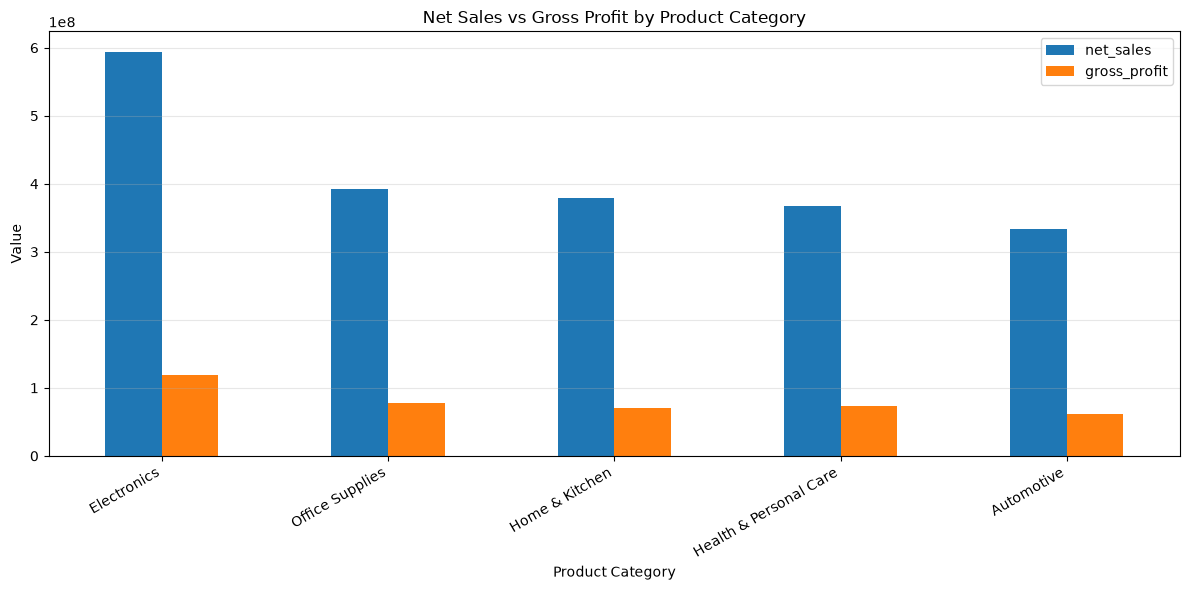

In [26]:
# Visualize category net sales and gross profit

category_chart = (
    category_profit
    .sort_values("net_sales", ascending=False)
    .set_index("category")
)

category_chart[
    ["net_sales", "gross_profit"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Net Sales vs Gross Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Value")
plt.xticks(rotation=30, ha="right")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

## Step 26 — Best & Worst Sales Performers Summary

Summarize the strongest and weakest performers across major sales dimensions.

This step consolidates key findings from the completed analyses and prepares the notebook for final business insights.

In [27]:
# Identify best and worst sales performers

best_channel = channel_sales.loc[
    channel_sales["total_sales"].idxmax()
]

best_segment = segment_sales.loc[
    segment_sales["total_sales"].idxmax()
]

best_region = regional_sales.loc[
    regional_sales["total_sales"].idxmax()
]

best_category = category_sales.loc[
    category_sales["net_sales"].idxmax()
]

best_profit_category = category_profit.loc[
    category_profit["gross_profit"].idxmax()
]

highest_margin_category = category_profit.loc[
    category_profit["profit_margin_pct"].idxmax()
]

best_product = product_sales.loc[
    product_sales["net_sales"].idxmax()
]

best_profit_product = product_sales.loc[
    product_sales["gross_profit"].idxmax()
]


print("BEST SALES PERFORMERS SUMMARY\n")

print(
    f"Top Sales Channel       : "
    f"{best_channel['sales_channel']} "
    f"({best_channel['total_sales']:,.2f})"
)

print(
    f"Top Customer Segment    : "
    f"{best_segment['customer_segment']} "
    f"({best_segment['total_sales']:,.2f})"
)

print(
    f"Top Customer Region     : "
    f"{best_region['region']} "
    f"({best_region['total_sales']:,.2f})"
)

print(
    f"Top Product Category    : "
    f"{best_category['category']} "
    f"({best_category['net_sales']:,.2f})"
)

print(
    f"Top Profit Category     : "
    f"{best_profit_category['category']} "
    f"({best_profit_category['gross_profit']:,.2f})"
)

print(
    f"Highest Margin Category : "
    f"{highest_margin_category['category']} "
    f"({highest_margin_category['profit_margin_pct']:.2f}%)"
)

print(
    f"Top Selling Product     : "
    f"{best_product['product_name']} "
    f"({best_product['net_sales']:,.2f})"
)

print(
    f"Top Profit Product      : "
    f"{best_profit_product['product_name']} "
    f"({best_profit_product['gross_profit']:,.2f})"
)

BEST SALES PERFORMERS SUMMARY

Top Sales Channel       : Online (645,216,635.68)
Top Customer Segment    : Retail (769,761,383.63)
Top Customer Region     : South (582,177,703.91)
Top Product Category    : Electronics (594,394,618.00)
Top Profit Category     : Electronics (118,620,407.99)
Highest Margin Category : Electronics (19.96%)
Top Selling Product     : Smart Devices Product 0228 (44,867,981.77)
Top Profit Product      : Smart Devices Product 0228 (12,663,765.97)


## Step 27 — Sales Analysis Reconciliation

Validate that key financial and volume totals reconcile across the Sales Orders and Sales Order Items datasets.

This ensures that the analyses performed at different levels of granularity remain internally consistent.

In [28]:
# Reconcile order-level and line-level sales totals

order_level_sales = sales_orders["order_value"].sum()

line_level_sales = sales_order_items[
    "net_order_value"
].sum()

order_level_units = sales_orders[
    "ordered_qty"
].sum()

line_level_units = sales_order_items[
    "ordered_qty"
].sum()


sales_difference = (
    order_level_sales - line_level_sales
)

units_difference = (
    order_level_units - line_level_units
)


print("SALES ANALYSIS RECONCILIATION\n")

print(
    f"Order-Level Sales     : "
    f"{order_level_sales:,.2f}"
)

print(
    f"Line-Level Net Sales  : "
    f"{line_level_sales:,.2f}"
)

print(
    f"Sales Difference      : "
    f"{sales_difference:,.2f}"
)

print()

print(
    f"Order-Level Units     : "
    f"{order_level_units:,}"
)

print(
    f"Line-Level Units      : "
    f"{line_level_units:,}"
)

print(
    f"Units Difference      : "
    f"{units_difference:,}"
)


reconciliation_passed = (
    abs(sales_difference) < 0.01
    and units_difference == 0
)


print(
    "\nRECONCILIATION STATUS :",
    "PASSED"
    if reconciliation_passed
    else "REVIEW REQUIRED"
)

SALES ANALYSIS RECONCILIATION

Order-Level Sales     : 2,068,495,699.27
Line-Level Net Sales  : 2,068,495,699.27
Sales Difference      : 0.00

Order-Level Units     : 501,755
Line-Level Units      : 501,755
Units Difference      : 0

RECONCILIATION STATUS : PASSED


## Step 28 — Key Business Insights

### Overall Sales Performance

The business generated approximately **2.07 billion in total sales** from **25,000 orders**, representing **501,755 units ordered** across **2,500 customers**.

Average Order Value was approximately **82.74K**, with an average of **20.07 units per order**.

### Sales Growth

Comparable January–September sales increased by **2.51% in 2025 compared with 2024**.

For January–September 2026, sales declined slightly by **0.23% compared with the same period in 2025**, indicating broadly stable sales performance rather than a significant decline.

### Sales Channel Performance

The **Online channel** generated the highest sales value at approximately **645.22M**, contributing **31.19% of total sales**.

The **Direct channel** recorded the highest Average Order Value at approximately **84.92K**.

### Customer Performance

The **Retail segment** was the largest customer segment, generating approximately **769.76M**, or **37.21% of total sales**.

The **South region** generated the highest regional sales at approximately **582.18M**, contributing **28.14% of total sales**.

Customer concentration risk is low: the **Top 10 customers contributed only 1.03% of total sales**, indicating a highly diversified customer base.

### Product Performance

**Electronics** was the strongest product category, generating approximately **594.39M in net sales** and **118.62M in gross profit**.

Electronics also achieved the highest category profit margin at approximately **19.96%**.

**Smart Devices Product 0228** was both the highest-selling and highest-profit product, generating approximately **44.87M in net sales** and **12.66M in gross profit**.

The Top 10 products contributed **11.38% of total sales**, suggesting that product revenue is reasonably diversified rather than dependent on a small number of SKUs.

### Profitability

Overall gross profit was approximately **400.86M**, producing an overall gross profit margin of **19.38%**.

Out of **61,397 sales order lines**, **60,897 were profitable**, while only **500 were loss-making**.

The total gross loss generated by loss-making lines was approximately **331.28K**, which is small relative to total gross profit.

### Discount Impact

Profitability declined consistently as discount levels increased.

Aggregate profit margin decreased from approximately **23.05% at 0% discount** to **9.48% at 15% discount**.

This indicates that aggressive discounting materially compresses margins and should be monitored when evaluating promotional or pricing strategies.

### Key Business Takeaway

Sales performance is broadly stable, with diversified customer and product revenue exposure.

The strongest commercial opportunities are concentrated in the **Online channel, Retail customer segment, South region, and Electronics category**.

The primary profitability consideration is discount management, as higher discount levels significantly reduce profit margins even though overall portfolio profitability remains strong.

## Step 29 — Final Sales Analysis Validation

Perform final validation of the Sales Analysis notebook.

The validation confirms that:

- Sales Orders and Sales Order Items retain their expected row counts.
- Order-level and line-level sales totals reconcile.
- Order-level and line-level unit totals reconcile.
- Customer and product enrichment produced no unmatched records.
- Core sales and profitability metrics contain valid values.

In [29]:
# Final Sales Analysis validation

validation_checks = {
    "Sales Orders Row Count":
        len(sales_orders) == 25000,

    "Sales Order Items Row Count":
        len(sales_order_items) == 61397,

    "Sales Totals Reconcile":
        abs(
            sales_orders["order_value"].sum()
            - sales_order_items["net_order_value"].sum()
        ) < 0.01,

    "Unit Totals Reconcile":
        sales_orders["ordered_qty"].sum()
        == sales_order_items["ordered_qty"].sum(),

    "Customer Segment Merge Complete":
        sales_customer["customer_segment"].isna().sum() == 0,

    "Customer Region Merge Complete":
        sales_region["region"].isna().sum() == 0,

    "Product Category Merge Complete":
        sales_product["category"].isna().sum() == 0,

    "Product Name Merge Complete":
        sales_product["product_name"].isna().sum() == 0,

    "Profit Margin Missing Values":
        sales_order_items["profit_margin_pct"].isna().sum() == 0
}


print("FINAL SALES ANALYSIS VALIDATION\n")

for check, result in validation_checks.items():
    print(
        f"{check:<35} : "
        f"{'PASS' if result else 'FAIL'}"
    )


final_status = all(
    validation_checks.values()
)


print(
    "\nFINAL SALES ANALYSIS STATUS :",
    "PASSED"
    if final_status
    else "REVIEW REQUIRED"
)

FINAL SALES ANALYSIS VALIDATION

Sales Orders Row Count              : PASS
Sales Order Items Row Count         : PASS
Sales Totals Reconcile              : PASS
Unit Totals Reconcile               : PASS
Customer Segment Merge Complete     : PASS
Customer Region Merge Complete      : PASS
Product Category Merge Complete     : PASS
Product Name Merge Complete         : PASS
Profit Margin Missing Values        : PASS

FINAL SALES ANALYSIS STATUS : PASSED
